In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')   # Ignore warnings for cleaner output

sns.set_style('whitegrid')
%matplotlib inline

In [2]:

train=pd.read_csv("../data/raw/train.csv")
test=pd.read_csv("../data/raw/test.csv")
gender_submission=pd.read_csv("../data/raw/gender_submission.csv")

print("Train shape", train.shape) #891 training row (passengers),12 columns
print("Test shape", test.shape)
print("Gender submission shape",gender_submission.shape)

Train shape (891, 12)
Test shape (418, 11)
Gender submission shape (418, 2)


In [3]:
print(train.columns)

print("\nMissing values in train:")
print(train.isnull().sum().sort_values(ascending=False))

print("\nMissing percentage in train:")
print((train.isnull().mean() * 100).sort_values(ascending=False).round(2))

print("\nMissing values in test:")
print(test.isnull().sum().sort_values(ascending=False))

print("\nMissing percentage in test:")
print((test.isnull().mean() * 100).sort_values(ascending=False).round(2))

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

Missing values in train:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64

Missing percentage in train:
Cabin          77.10
Age            19.87
Embarked        0.22
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
dtype: float64

Missing values in test:
Cabin          327
Age             86
Fare             1
PassengerId      0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Embarked         0
dtype: int64

Missing percentage in test:
Cabin  

In [4]:
train["Survived"].value_counts()
(train["Survived"].value_counts(normalize=True) * 100).round(2)

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

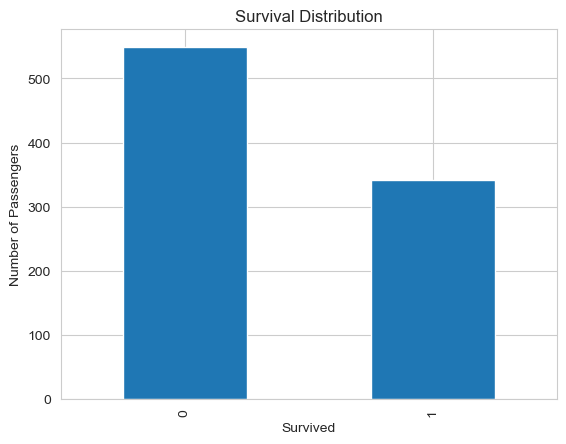

In [5]:
train["Survived"].value_counts().plot(kind="bar")

plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

In [6]:
train["Sex"].value_counts()
pd.crosstab(train["Sex"], train["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [7]:
(
    pd.crosstab(
        train["Sex"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
Sex,,
female,25.80,74.20
male,81.11,18.89


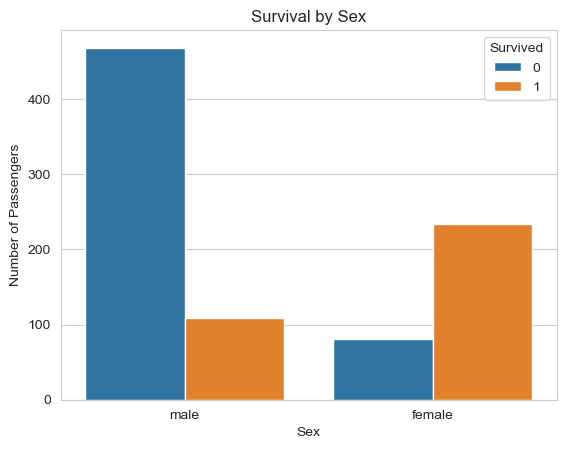

In [8]:
sns.countplot(data=train, x="Sex", hue="Survived") #To compare how survival rates differ between men and women side-by-side., hue=cplor coding
plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")

plt.show()

In [9]:
#Does passenger class have a relationship with survival?
train["Pclass"].value_counts().sort_index()

Pclass
1    216
2    184
3    491
Name: count, dtype: int64

In [10]:
pd.crosstab(train["Pclass"], train["Survived"])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [11]:
(
    pd.crosstab(
        train["Pclass"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
Pclass,,
1,37.04,62.96
2,52.72,47.28
3,75.76,24.24


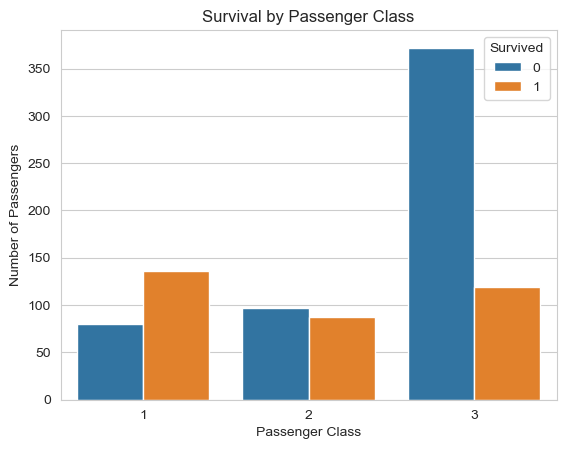

In [12]:
sns.countplot(data=train, x="Pclass", hue="Survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

In [13]:
#Does age have a relationship with survival?
train["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

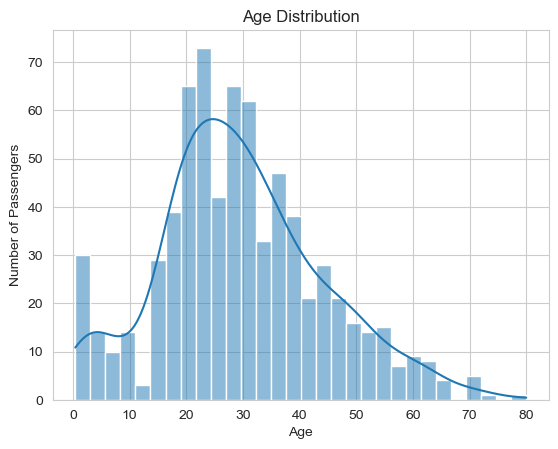

In [14]:
sns.histplot(data=train, x="Age", bins=30, kde=True) #kde=smooth trend line over the bars

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

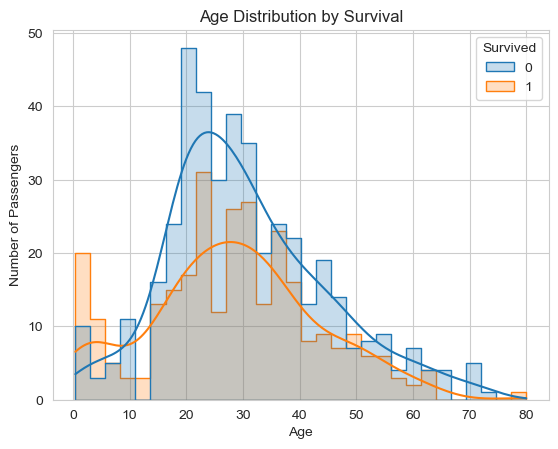

In [15]:
sns.histplot(
    data=train,
    x="Age",
    hue="Survived",
    bins=30,
    kde=True,
    element="step" #changes the visual style of overlapping bars into a clean outlined step line
)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [16]:
train["AgeGroup"] = pd.cut(    #pd.cut() converts continuous numerical data into categorical bins (ranges).
    train["Age"],
    bins=[0, 12, 18, 35, 60, 100], #Age > 0 and Age <= 12 = child
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)
#This is our first real feature engineering! created new column age to AgeGroup 
#Why are we doing this?
#Sometimes raw numerical values are harder to interpret.

In [17]:
(
    pd.crosstab(
        train["AgeGroup"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
AgeGroup,,
Child,42.03,57.97
Teen,57.14,42.86
Young Adult,61.73,38.27
Adult,60.00,40.00
Senior,77.27,22.73


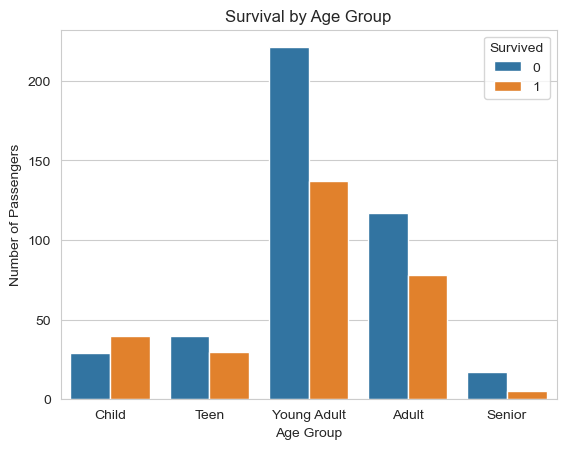

In [18]:
sns.countplot(
    data=train,
    x="AgeGroup",
    hue="Survived",
    order=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

plt.title("Survival by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")

plt.show()

In [19]:
#We created:
#train["AgeGroup"]
#but we haven't decided yet whether the model should actually use it.
#That's important.
#Feature engineering isn't:
#"Create every possible column."
#It's:
#Create meaningful representations of the underlying information and later test whether they improve generalization.

In [20]:
# so far we looked at:
#Sex → Survival
#Pclass → Survival
#Age → Survival
#Multivariate analysis means analyzing three or more variables together at the same time to discover complex relationships.
#Sex + Pclass = explain survival better
pd.crosstab(
    [train["Sex"], train["Pclass"]], #Groups rows by two variables simultaneously (multivariate grouping).
    train["Survived"],
    normalize="index"
).mul(100).round(2)

Survived           0      1
Sex    Pclass              
female 1        3.19  96.81
       2        7.89  92.11
       3       50.00  50.00
male   1       63.11  36.89
       2       84.26  15.74
       3       86.46  13.54

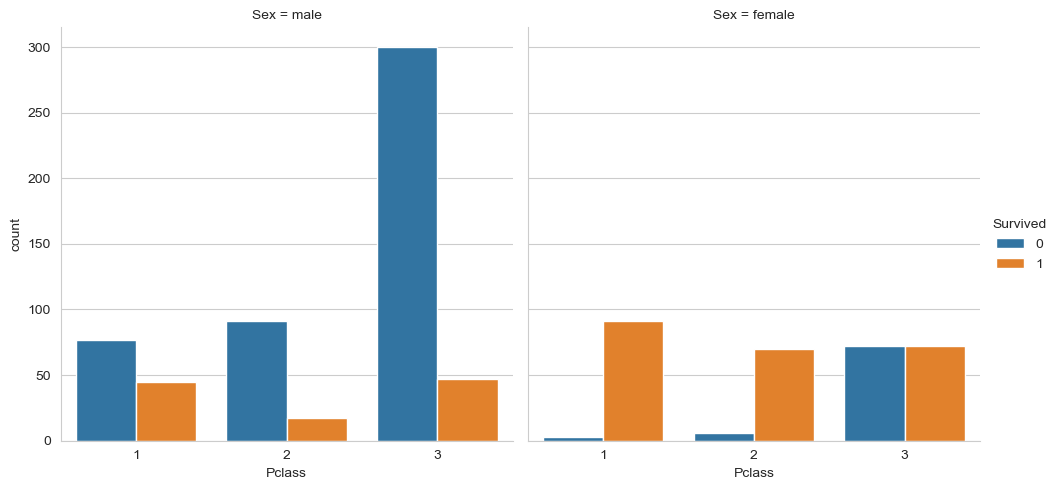

In [21]:
sns.catplot(
    data=train,
    x="Pclass",
    hue="Survived",
    col="Sex", #creates separate panels
    kind="count"
)
plt.show()

In [22]:
survival_by_sex_class = (
    train.groupby(["Sex", "Pclass"])["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

survival_by_sex_class

Sex     Pclass
female  1         96.81
        2         92.11
        3         50.00
male    1         36.89
        2         15.74
        3         13.54
Name: Survived, dtype: float64

In [23]:
train[["SibSp","Parch"]].describe()

,SibSp,Parch
count,891.000000,891.000000
mean,0.523008,0.381594
std,1.102743,0.806057
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,0.000000
max,8.000000,6.000000


In [24]:
print("SibSp:")
print(train["SibSp"].value_counts().sort_index())

print("\nParch:")
print(train["Parch"].value_counts().sort_index())

SibSp:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

Parch:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64


In [25]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1 # 1 for passenger thrmselves Suppose Roshan is travelling with:1 sibling2 parents/children

In [26]:
#Before:SibSp 1 Parch 2
#After:SibSp1    Parch 2   FamilySize 4 
#we've created a new feature.
#This is our first major example of: fearure engineering

In [27]:
train[["SibSp","Parch","FamilySize"]].head(10)

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1
5,0,0,1
6,0,0,1
7,3,1,5
8,0,2,3
9,1,0,2


In [28]:
(
    train.groupby("FamilySize")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64

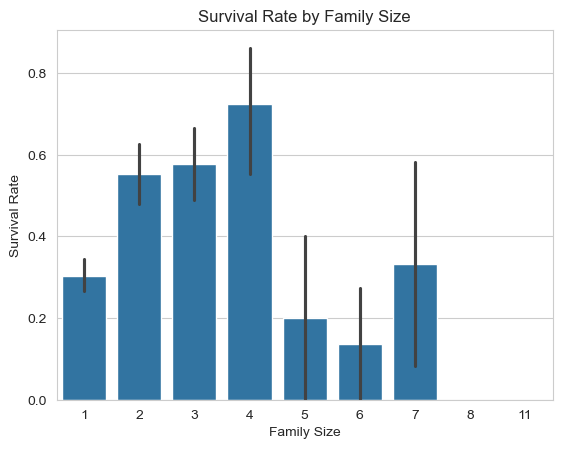

In [29]:
sns.barplot(
    data=train,
    x="FamilySize",
    y="Survived"
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

In [30]:
#observation
#Small family       → higher survival
#Medium family      → possibly higher survival
#Very large family  → lower survival

In [31]:
train["IsAlone"] = (train["FamilySize"] == 1).astype(int)

In [32]:
(
    train.groupby("IsAlone")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

IsAlone
0    50.56
1    30.35
Name: Survived, dtype: float64

In [33]:
train["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

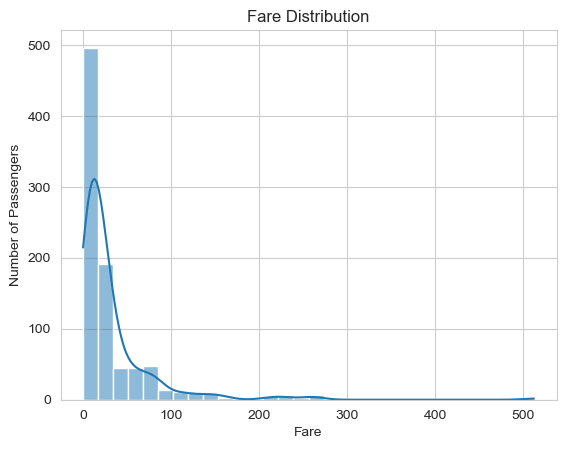

In [34]:
sns.histplot(data=train, x="Fare", bins=30, kde=True)

plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")

plt.show() #positively/right-skewed distribution.

In [35]:
train["FareGroup"] = pd.qcut( #qcut divides the data into quantiles,approximately equal number of observations per group
    train["Fare"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

In [36]:
(
    train.groupby("FareGroup", observed=True)["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

FareGroup
Low            19.73
Medium-Low     30.36
Medium-High    45.50
High           58.11
Name: Survived, dtype: float64

In [37]:
train["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [38]:
(
    pd.crosstab(
        train["Embarked"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
Embarked,,
C,44.64,55.36
Q,61.04,38.96
S,66.30,33.70


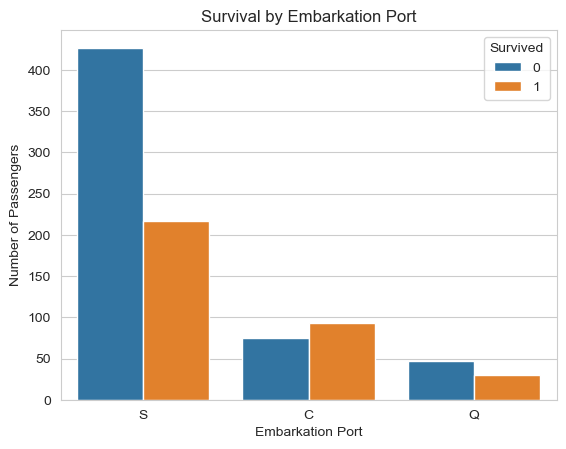

In [39]:
sns.countplot(
    data=train,
    x="Embarked",
    hue="Survived"
)

plt.title("Survival by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Number of Passengers")

plt.show()

In [40]:
#extracting title from namw
train["Name"].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: object

In [41]:
train["Title"] = train["Name"].str.extract(r",\s*([^.]*)\.") #incopy 

In [42]:
train["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [43]:
(
    pd.crosstab(
        train["Title"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
Title,,
Capt,100.00,0.00
Col,50.00,50.00
Don,100.00,0.00
Dr,57.14,42.86
Jonkheer,100.00,0.00
Lady,0.00,100.00
Major,50.00,50.00
Master,42.50,57.50
Miss,30.22,69.78


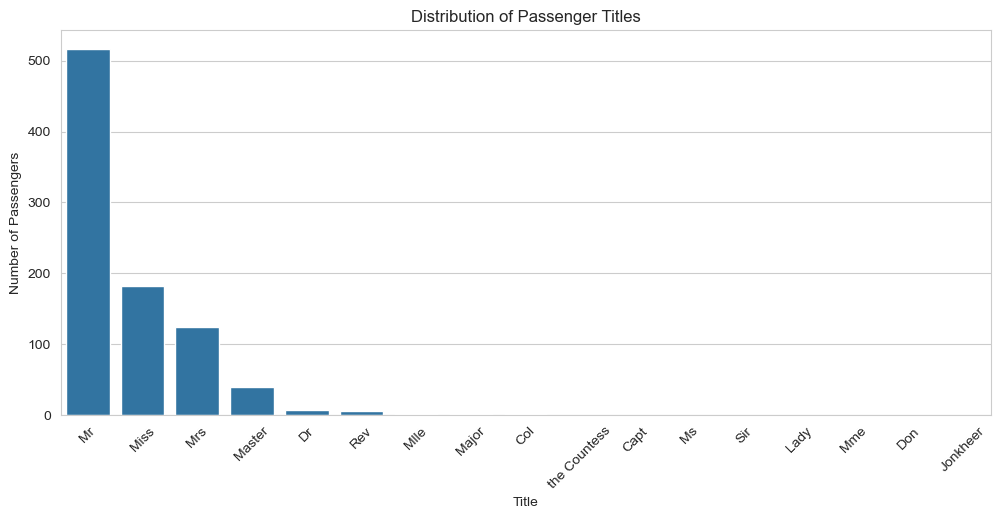

In [44]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=train,
    x="Title",
    order=train["Title"].value_counts().index
)

plt.title("Distribution of Passenger Titles")
plt.xlabel("Title")
plt.ylabel("Number of Passengers")

plt.xticks(rotation=45)

plt.show()

In [45]:
title_counts = train["Title"].value_counts()

train["Title"] = train["Title"].where(
    train["Title"].isin(["Mr", "Miss", "Mrs", "Master"]),
    "Rare"
)

In [46]:
(
    pd.crosstab(
        train["Title"],
        train["Survived"],
        normalize="index"
    ) * 100
).round(2)

Survived,0,1
Title,,
Master,42.50,57.50
Miss,30.22,69.78
Mr,84.33,15.67
Mrs,20.80,79.20
Rare,55.56,44.44


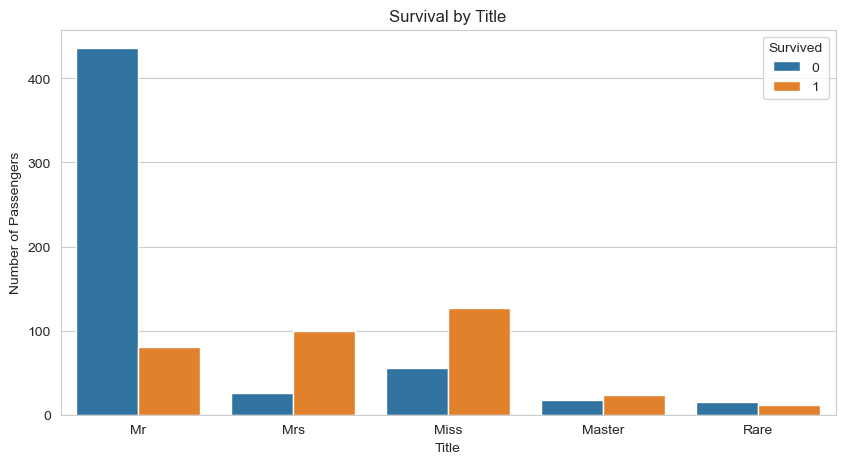

In [47]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=train,
    x="Title",
    hue="Survived"
)

plt.title("Survival by Title")
plt.xlabel("Title")
plt.ylabel("Number of Passengers")

plt.show()

In [ ]:
#01_exploratory_data_analysis.ipynb
#Contains:
#- Load raw data
#- Dataset shape and structure
#- Missing-value analysis
#- Target distribution
#- Survival analysis by sex, class, age, family, fare, and embarkation
#- EDA charts and findings